In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
%cd /content/drive/MyDrive/DM_Assignment/

/content/drive/MyDrive/DM_Assignment


## Task 1: Association Rule Mining

In [5]:
import pandas as pd

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

from IPython.display import display

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [23]:
import warnings

# this part is needed otherwise we would face too many this kind of warning in the following code
warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    message=r"datetime\.datetime\.utcnow\(\) is deprecated",
    module=r"jupyter_client\.session"
)

In [24]:
data = pd.read_csv("Grocery_Items_3.csv")

transactions = []

for row_number, row in data.iterrows():
  pool = set()

  for item in row:
    if pd.notna(item):
        item_name = str(item).strip()

        if item_name != "":
            pool.add(item_name)

  transactions.append(sorted(pool))

In [25]:
# Boolean table form is expected by Mlxtend
encoder = TransactionEncoder()

encoded_transactions = encoder.fit(transactions).transform(transactions)

pool_table = pd.DataFrame(encoded_transactions,columns=encoder.columns_)

### Dataset exploration — part (a)

In [26]:
number_of_transactions = len(pool_table)
number_of_unique_items = len(pool_table.columns)

item_counts = pool_table.sum(axis=0)

top_three_items = (
    item_counts
    .sort_values(ascending=False)
    .head(3)
    .reset_index()
)

top_three_items.columns = [
    "Item",
    "Transaction count"
]

print("Number of transactions:", number_of_transactions)
print("Number of unique items:", number_of_unique_items)

display(top_three_items)

Number of transactions: 8000
Number of unique items: 164


,Item,Transaction count
0,whole milk,1283
1,other vegetables,975
2,rolls/buns,909


As we can see, the number of transactions in the dataset is 8000. The number of unique items is 164 and the three most frequently purchases itens are whole mike (1283), other vegatables (975), and rolls/buns (909) respectively.

### Association rule generation — part (b)

In [27]:
min_support = 0.005

frequent_itemsets = apriori(pool_table, min_support=min_support, use_colnames=True)

print(
    "Number of frequent itemsets:",
    len(frequent_itemsets)
)

display(
    frequent_itemsets
    .sort_values("support", ascending=False)
    .head(10)
)

Number of frequent itemsets: 126


,support,itemsets
86,0.160375,(whole milk)
53,0.121875,(other vegetables)
65,0.113625,(rolls/buns)
74,0.097000,(soda)
87,0.079250,(yogurt)
66,0.071500,(root vegetables)
81,0.064000,(tropical fruit)
69,0.061500,(sausage)
6,0.060875,(bottled water)
19,0.053250,(citrus fruit)


In [28]:
min_confidence = 0.10

rules = association_rules(
    frequent_itemsets,
    num_itemsets=number_of_transactions,
    metric="confidence",
    min_threshold=min_confidence
)

print("Total number of association rules:", len(rules))

Total number of association rules: 23


In [29]:
top_five_rules = (
    rules
    .sort_values("lift", ascending=False)
    .head(5)
    .copy()
)

def format_items(items):
    return ", ".join(sorted(items))

top_five_rules["antecedents"] = (top_five_rules["antecedents"].apply(format_items))

top_five_rules["consequents"] = (top_five_rules["consequents"].apply(format_items))

display(
    top_five_rules[
        [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
        ]
    ].round(6)
)

,antecedents,consequents,support,confidence,lift
17,sausage,soda,0.00675,0.109756,1.131506
0,bottled beer,whole milk,0.00750,0.164384,1.024995
18,sausage,whole milk,0.01000,0.162602,1.013884
5,curd,whole milk,0.00525,0.158491,0.988250
8,newspapers,whole milk,0.00600,0.156863,0.978100


### Parameter sensitivity analysis - part (c)

In [30]:
import seaborn as sns

support_values = [0.002, 0.005, 0.01]
confidence_values = [0.05, 0.10, 0.15]

sensitivity_results = []

for support in support_values:
    itemsets_for_support = apriori(
        pool_table,
        min_support=support,
        use_colnames=True
    )

    for confidence in confidence_values:
        rules_for_setting = association_rules(
            itemsets_for_support,
            num_itemsets=len(pool_table),
            metric="confidence",
            min_threshold=confidence
        )

        sensitivity_results.append({
            "Minimum support": support,
            "Minimum confidence": confidence,
            "Number of rules": len(rules_for_setting)
        })

sensitivity_table = pd.DataFrame(sensitivity_results)

display(sensitivity_table)


,Minimum support,Minimum confidence,Number of rules
0,0.002,0.05,236
1,0.002,0.10,65
2,0.002,0.15,11
3,0.005,0.05,56
4,0.005,0.10,23
5,0.005,0.15,5
6,0.010,0.05,12
7,0.010,0.10,5
8,0.010,0.15,1


In [31]:
heatmap_table = sensitivity_table.pivot(
    index="Minimum confidence",
    columns="Minimum support",
    values="Number of rules"
)

heatmap_table = heatmap_table.reindex(
    index=confidence_values,
    columns=support_values
)

display(heatmap_table)

Minimum support,0.002,0.005,0.010
Minimum confidence,,,
0.05,236,56,12
0.10,65,23,5
0.15,11,5,1


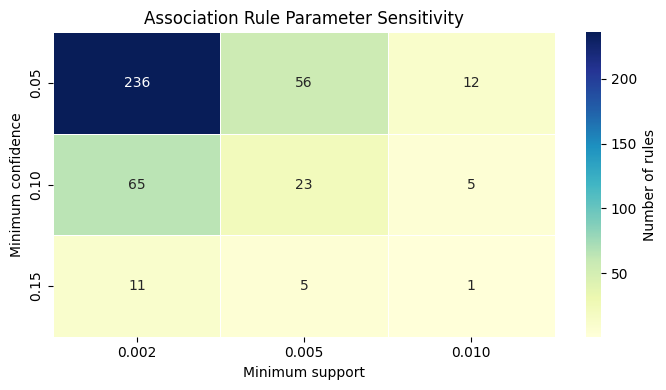

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

sns.heatmap(
    heatmap_table,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5,
    xticklabels=["0.002", "0.005", "0.010"],
    yticklabels=["0.05", "0.10", "0.15"],
    cbar_kws={"label": "Number of rules"}
)

plt.xlabel("Minimum support")
plt.ylabel("Minimum confidence")
plt.title("Association Rule Parameter Sensitivity")

plt.tight_layout()
plt.show()

### Interpretation - part (d)

(1) Ans: In this experiment, increasing either minimum support or minimum confidence reduces the number of qualifying rules. A higher minimum support requires item combinations to appear in more transactions. A higher minimum confidence requires a larger proportion of transactions containing the antecedent to also contain the consequent. In general, increasing either threshold can decrease the rule count when the other threshold is fixed.
\
(2) Ans: A rule can have high confidence but low lift when its consequent is already very common. For example, confidence of 75% may appear high, but if the consequent occurs in 80% of all transactions, the lift is only 0.9375. Thus, the consequent is actually less likely when the antecedent is present than it is. High confidence alone does not establish a useful positive association.

## Task 2: Image Classification Using CNN

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from IPython.display import display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [9]:
dataset_path = Path("data/processed/cifar10_first4class_first50images.npz")

data = np.load(dataset_path)

images = data["images"]
labels = data["labels"]

# Convert pixel values from [0, 255] to [0, 1].
X = images.astype("float32") / 255.0
y = labels.copy()

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

X_train = torch.tensor(X_train).permute(0, 3, 1, 2).contiguous()
X_val = torch.tensor(X_val).permute(0, 3, 1, 2).contiguous()

y_train = torch.tensor(y_train, dtype=torch.long)
y_val = torch.tensor(y_val, dtype=torch.long)

print("Training image shape:", X_train.shape)
print("Validation image shape:", X_val.shape)
print("Training label shape:", y_train.shape)

Training image shape: torch.Size([160, 3, 32, 32])
Validation image shape: torch.Size([40, 3, 32, 32])
Training label shape: torch.Size([160])


In [10]:
batch_size = 32

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

train_eval_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)

val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [13]:
def build_base_cnn(hidden_neurons):
    model = nn.Sequential(
      # Input: 3 × 32 × 32
      nn.Conv2d(
          in_channels=3,
          out_channels=8,
          kernel_size=3,
          padding=0
      ),
      nn.ReLU(),

      # 8 × 30 × 30 -> 8 × 15 × 15
      nn.MaxPool2d(kernel_size=2, stride=2),

      nn.Conv2d(
          in_channels=8,
          out_channels=8,
          kernel_size=3,
          padding=0
      ),
      nn.ReLU(),

      # 8 × 13 × 13 -> 8 × 6 × 6
      nn.MaxPool2d(kernel_size=2, stride=2),

      nn.Flatten(),

      # Flattened size: 8 × 6 × 6 = 288
      nn.Linear(288, hidden_neurons),
      nn.ReLU(),

      nn.Linear(hidden_neurons, 4)
    )

    return model

def calculate_accuracy(model, data_loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
      for batch_images, batch_labels in data_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        logits = model(batch_images)

        predictions = logits.argmax(dim=1)

        correct += (predictions == batch_labels).sum().item()
        total += batch_labels.size(0)

    return correct / total

The last digit of the Banner ID is 8.
\
Therefore, the two selected model variants are those with 8 and 32 neurons, respectively, in the fully connected layer.

In [14]:
epochs = 20

model_settings = [
    ("Baseline: 16 neurons", 16),
    ("CNN: 8 neurons", 8),
    ("CNN: 32 neurons", 32)
]

models = {}
histories = {}
results = []

for model_name, hidden_neurons in model_settings:
    print("\nTraining:", model_name)

    model = build_base_cnn(hidden_neurons).to(device)

    loss_function = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
    )

    history = {
        "train_accuracy": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):
        model.train()

        for batch_images, batch_labels in train_loader:
          batch_images = batch_images.to(device)
          batch_labels = batch_labels.to(device)

          optimizer.zero_grad()

          logits = model(batch_images)
          loss = loss_function(logits, batch_labels)

          loss.backward()
          optimizer.step()

        train_accuracy = calculate_accuracy(model, train_eval_loader)

        val_accuracy = calculate_accuracy(model, val_loader)

        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Training accuracy: {train_accuracy:.4f} | "
            f"Validation accuracy: {val_accuracy:.4f}"
        )

    parameter_count = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    models[model_name] = model
    histories[model_name] = history

    results.append({
        "Model": model_name,
        "Trainable parameters": parameter_count,
        "Final training accuracy (%)":
            history["train_accuracy"][-1] * 100,
        "Final validation accuracy (%)":
            history["val_accuracy"][-1] * 100
    })


Training: Baseline: 16 neurons
Epoch 01/20 | Training accuracy: 0.2500 | Validation accuracy: 0.2500
Epoch 02/20 | Training accuracy: 0.2500 | Validation accuracy: 0.2500
Epoch 03/20 | Training accuracy: 0.2500 | Validation accuracy: 0.2500
Epoch 04/20 | Training accuracy: 0.2500 | Validation accuracy: 0.2500
Epoch 05/20 | Training accuracy: 0.2812 | Validation accuracy: 0.2750
Epoch 06/20 | Training accuracy: 0.3812 | Validation accuracy: 0.4000
Epoch 07/20 | Training accuracy: 0.3563 | Validation accuracy: 0.3500
Epoch 08/20 | Training accuracy: 0.3750 | Validation accuracy: 0.3250
Epoch 09/20 | Training accuracy: 0.4062 | Validation accuracy: 0.3500
Epoch 10/20 | Training accuracy: 0.4437 | Validation accuracy: 0.4250
Epoch 11/20 | Training accuracy: 0.4188 | Validation accuracy: 0.4500
Epoch 12/20 | Training accuracy: 0.4688 | Validation accuracy: 0.5000
Epoch 13/20 | Training accuracy: 0.4250 | Validation accuracy: 0.4750
Epoch 14/20 | Training accuracy: 0.4375 | Validation accur

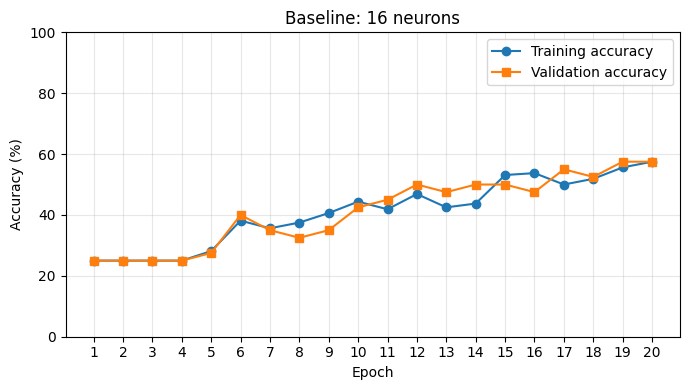

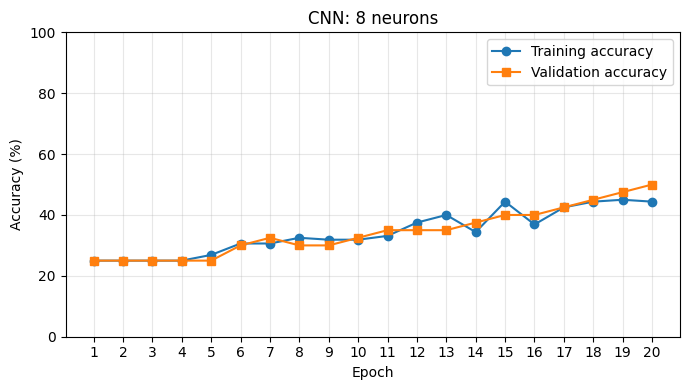

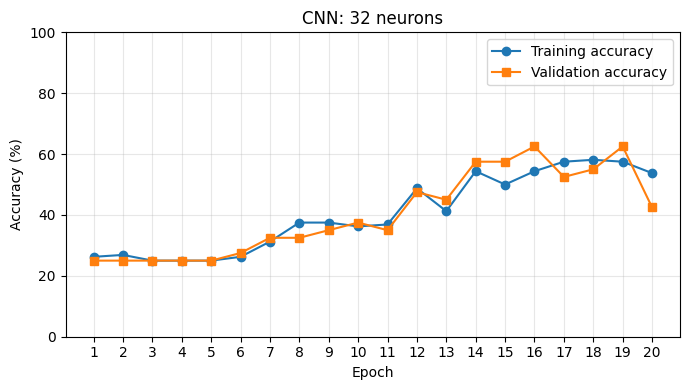

In [15]:
for model_name, history in histories.items():
  epoch_numbers = range(1, len(history["train_accuracy"]) + 1)

  train_accuracy = np.array(history["train_accuracy"]) * 100

  val_accuracy = np.array(history["val_accuracy"]) * 100

  plt.figure(figsize=(7, 4))

  plt.plot(
      epoch_numbers,
      train_accuracy,
      marker="o",
      label="Training accuracy"
  )

  plt.plot(
      epoch_numbers,
      val_accuracy,
      marker="s",
      label="Validation accuracy"
  )

  plt.xlabel("Epoch")
  plt.ylabel("Accuracy (%)")
  plt.title(model_name)

  plt.xticks(list(epoch_numbers))
  plt.ylim(0, 100)
  plt.grid(alpha=0.3)
  plt.legend()

  plt.tight_layout()
  plt.show()

In [16]:
results_table = pd.DataFrame(results)

display(results_table.round(2))

,Model,Trainable parameters,Final training accuracy (%),Final validation accuracy (%)
0,Baseline: 16 neurons,5500,57.50,57.5
1,CNN: 8 neurons,3156,44.38,50.0
2,CNN: 32 neurons,10188,53.75,42.5


### d(1)
Ans: The baseline CNN with 16 hidden neurons achieves the highest final validation accuracy of 57.5%. by comparison, the 8-neuron model reached an accuracy of 50.0%, while the 32-neuron model attained 42.5%.

### d(2)
Ans: No. Increasing the number of trainable parameters from 3,156 to 5,500 improves final validation accuracy from 50.0% to 57.5%. However, increasing it further to 10,188 reduces final validation accuracy to 42.5%. Therefore, a larger model does not necessarily generalize better.

### d(3)
Ans: For the baseline model with 16 neurons, neither is clearly established.	Training and validation accuracy generally improve together and both finish at 57.5%. As for the model with 8 neurons, there are signs of underfitting since
training accuracy remains relatively low at 44.38%, with validation accuracy at 50.0%. And for the model with 32 neurons, there could be possible late overfitting, with unstable validation performance.

## Task 3: Multi-Label Text Classification Using BERT

In [25]:
from datasets import load_dataset, Features, Sequence, Value

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)

from sklearn.metrics import accuracy_score, f1_score

In [26]:
dataset = load_dataset(
    "json",
    data_files={
        "train": "student_3/train.json",
        "validation": "student_3/validation.json",
        "test": "student_3/test.json"
    }
)

print(dataset)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['ID', 'Tweet', 'anger', 'anticipation', 'disgust', 'fear', 'joy', 'love', 'optimism', 'pessimism', 'sadness', 'surprise', 'trust'],
        num_rows: 3000
    })
    validation: Dataset({
        features: ['ID', 'Tweet', 'anger', 'anticipation', 'disgust', 'fear', 'joy', 'love', 'optimism', 'pessimism', 'sadness', 'surprise', 'trust'],
        num_rows: 400
    })
    test: Dataset({
        features: ['ID', 'Tweet', 'anger', 'anticipation', 'disgust', 'fear', 'joy', 'love', 'optimism', 'pessimism', 'sadness', 'surprise', 'trust'],
        num_rows: 1500
    })
})


In [27]:
label_columns = [
    "anger",
    "anticipation",
    "disgust",
    "fear",
    "joy",
    "love",
    "optimism",
    "pessimism",
    "sadness",
    "surprise",
    "trust"
]

id2label = {
    index: label
    for index, label in enumerate(label_columns)
}

label2id = {
    label: index
    for index, label in enumerate(label_columns)
}

In [30]:
model_name = "google-bert/bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

def preprocess_data(examples):
    texts = examples["Tweet"]

    encoding = tokenizer(
        texts,
        padding="max_length",
        truncation=True,
        max_length=128
    )

    labels_matrix = np.zeros(
        (len(texts), len(label_columns)),
        dtype=np.float32
    )

    for column_index, label_name in enumerate(label_columns):
        labels_matrix[:, column_index] = examples[label_name]

    encoding["labels"] = labels_matrix.tolist()

    return encoding

encoded_features = Features({
    "input_ids": Sequence(Value("int64")),
    "token_type_ids": Sequence(Value("int64")),
    "attention_mask": Sequence(Value("int64")),
    "labels": Sequence(Value("float32"))
})

encoded_dataset = dataset.map(
    preprocess_data,
    batched=True,
    remove_columns=dataset["train"].column_names,
    features=encoded_features
)

encoded_dataset.set_format("torch")

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

In [31]:
example = encoded_dataset["train"][0]

print("Token shape:", example["input_ids"].shape)
print("Labels:", example["labels"])
print("Label dtype:", example["labels"].dtype)

Token shape: torch.Size([128])
Labels: tensor([0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.])
Label dtype: torch.float32


In [32]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    problem_type="multi_label_classification",
    num_labels=len(label_columns),
    id2label=id2label,
    label2id=label2id
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [34]:
def compute_metrics(evaluation_prediction):
    logits = evaluation_prediction.predictions

    if isinstance(logits, tuple):
        logits = logits[0]

    probabilities = torch.sigmoid(
        torch.tensor(logits)
    ).numpy()

    y_pred = (probabilities >= 0.5).astype(int)
    y_true = evaluation_prediction.label_ids.astype(int)

    exact_match_accuracy = accuracy_score(
        y_true,
        y_pred
    )

    matching_positives = (
        (y_pred == 1) & (y_true == 1)
    )

    at_least_one_accuracy = matching_positives.any(
        axis=1
    ).mean()

    micro_f1 = f1_score(
        y_true,
        y_pred,
        average="micro",
        zero_division=0
    )

    return {
        "exact_match_accuracy": float(exact_match_accuracy),
        "at_least_one_accuracy": float(at_least_one_accuracy),
        "micro_f1": float(micro_f1)
    }

### (a) Fine-tuning BERT



In [35]:
training_args = TrainingArguments(
    output_dir="output/bert_student_3",

    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",

    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=5,
    weight_decay=0.01,

    load_best_model_at_end=True,
    metric_for_best_model="micro_f1",
    greater_is_better=True,

    save_total_limit=2,
    report_to="none",
    seed=42
)

In [36]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=encoded_dataset["train"],
    eval_dataset=encoded_dataset["validation"],
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Exact Match Accuracy,At Least One Accuracy,Micro F1
1,0.422206,0.353497,0.207500,0.770000,0.627685
2,0.311624,0.321286,0.275000,0.850000,0.685843
3,0.261750,0.316097,0.280000,0.835000,0.675429
4,0.230628,0.314679,0.260000,0.857500,0.683915
5,0.211532,0.316146,0.267500,0.872500,0.689807


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

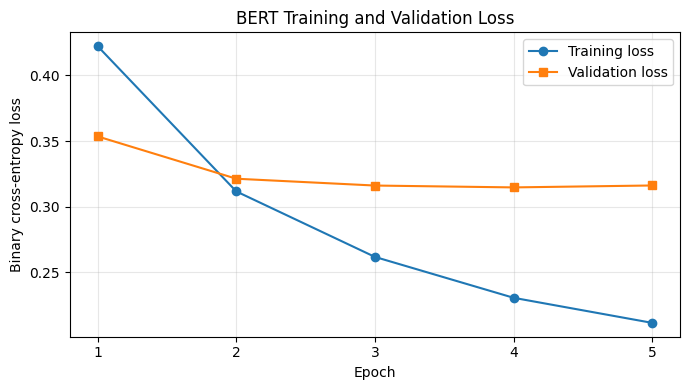

In [37]:
training_epochs = []
training_losses = []

validation_epochs = []
validation_losses = []

for record in trainer.state.log_history:
  if "loss" in record:
    training_epochs.append(record["epoch"])
    training_losses.append(record["loss"])

  if "eval_loss" in record:
    validation_epochs.append(record["epoch"])
    validation_losses.append(record["eval_loss"])

plt.figure(figsize=(7, 4))

plt.plot(
    training_epochs,
    training_losses,
    marker="o",
    label="Training loss"
)

plt.plot(
    validation_epochs,
    validation_losses,
    marker="s",
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("BERT Training and Validation Loss")

plt.xticks([1, 2, 3, 4, 5])
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [38]:
print(
    "Selected checkpoint:",
    trainer.state.best_model_checkpoint
)

print(
    "Best validation micro-F1:",
    trainer.state.best_metric
)

Selected checkpoint: output/bert_student_3/checkpoint-1875
Best validation micro-F1: 0.6898071625344353


### (b), (c), (d): Evaluate the test set

In [39]:
test_output = trainer.predict(
    encoded_dataset["test"]
)

test_metrics = test_output.metrics

In [40]:
exact_match_accuracy = test_metrics["test_exact_match_accuracy"]

at_least_one_accuracy = test_metrics["test_at_least_one_accuracy"]

micro_f1 = test_metrics["test_micro_f1"]

print(
    "Test exact-match accuracy:",
    f"{exact_match_accuracy:.4f}",
    f"({exact_match_accuracy * 100:.2f}%)"
)

print(
    "Test at-least-one-label accuracy:",
    f"{at_least_one_accuracy:.4f}",
    f"({at_least_one_accuracy * 100:.2f}%)"
)

print(
    "Test micro-F1:",
    f"{micro_f1:.4f}"
)

Test exact-match accuracy: 0.2673 (26.73%)
Test at-least-one-label accuracy: 0.8660 (86.60%)
Test micro-F1: 0.6931


In [41]:
metrics_table = pd.DataFrame({
    "Metric": [
        "Exact-match accuracy",
        "At-least-one-label accuracy",
        "Micro-F1"
    ],
    "Score": [
        exact_match_accuracy,
        at_least_one_accuracy,
        micro_f1
    ]
})

display(metrics_table.round(4))

,Metric,Score
0,Exact-match accuracy,0.2673
1,At-least-one-label accuracy,0.8660
2,Micro-F1,0.6931


### (e) Comparison and interpretation
Ans: The three metrics evaluate different aspects of multi-label classification. Exact-match accuracy is the strictest: a tweet classified as correct only when its entire predicted label set is correct. Consequently, this metric can be low even when many individual labels are predicted correctly.
\
At-least-one-label accuracy is much more relaxed. A tweet receives credit whenever at least one predicted emotion is correct. As for Micro-F1, it balances precision and recall by combining true positives, false positives, and false negatives across all tweets and labels. It gives credit for correctly identified emotions while penalizing both additional incorrect emotions and missed emotions.
\
I would prefer micro-F1 as the most informative metric since it summarizes overall emotion-detection performance, while the other two metrcs can only reflect the performance from certain perspectives.